# Implementación de un modelo de deep learning
Isral González Huerta A01751433

## Selección del dataset
Decidí utilizar Intel Image Classification dataset de Kaggle (https://www.kaggle.com/datasets/puneet6060/intel-image-classification) porque presenta un problema de clasficación con el que ya estoy familiarizado, no lo he usado en actividades anteriores y tiene volúmen suficiente de imágenes (alrededor de 25,000) como para que puedar decir con confianza que la mayoría de los problemas de rendimiento son producto de un error en mi arquitectura y no por falta de datos de entrenamiento y prueba.

In [5]:
import os
import kagglehub
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [8]:
# 1. Descargar la última versión del dataset
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

# 2. Definir las rutas exactas hacia las carpetas. El dataset ya vienve con separación para datos de entrenamiento, prueba y predicción.
train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")
pred_dir = os.path.join(path, "seg_pred", "seg_pred")

# Mostrar rutas
print("Clases en train:", os.listdir(train_dir))
print("Imágenes sueltas para predicción:", len(os.listdir(pred_dir)))

Clases en train: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Imágenes sueltas para predicción: 7301


El sitio de kaggle menciona que hay alrededor de 14,000 imágenes para entrenamiento, 3,000 de prueba y 7,000 para las predicciones. También afirma que hay esas mismas 6 categorías.

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Clases: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


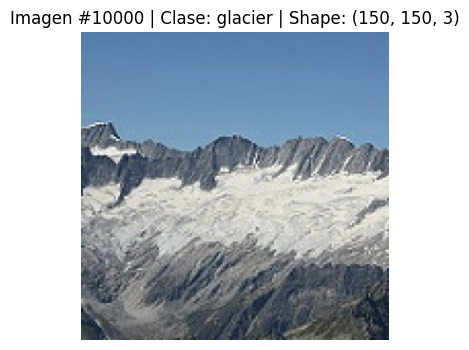

In [9]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

# Dataset de Entrenamiento (80% de seg_train)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Dataset de Validación (20% de seg_train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# 3. Dataset de Prueba (seg_test intacto)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Clases del dataset
class_names = train_ds.class_names
print("Clases:", class_names)

# Imágen de ejemplo del dataset de entrenamiento. Este código raro es necesario
# porque agrupétodo en batches. El idx controla que imágen mostrar
idx = 10000

for image, label in train_ds.unbatch().skip(idx).take(1):
    sample_image = image.numpy().astype("uint8")
    sample_label = class_names[label]

    plt.figure(figsize=(4, 4))
    plt.imshow(sample_image)
    plt.title(f"Imagen #{idx} | Clase: {sample_label} | Shape: {sample_image.shape}")
    plt.axis("off")
    plt.show()

## Implementar arquitectura de deep learning (keras + tensorflow)
Para esta sección enumeraré cada versión del modelo con el título "Versión x" y la acompañaré de una breve descripción sobre el cambio entre esa versión y la anterior.

### Versión 1
Prueba inicial para ver que todo funcione.

In [ ]:
model_base = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

model_base.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_base = model_base.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


c:\Users\mauve\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.6402 - loss: 0.9506 - val_accuracy: 0.6668 - val_loss: 0.8805
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.7604 - loss: 0.6496 - val_accuracy: 0.7160 - val_loss: 0.7787
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8074 - loss: 0.5200 - val_accuracy: 0.7798 - val_loss: 0.6057
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.8571 - loss: 0.3990 - val_accuracy: 0.7470 - val_loss: 0.7550
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.8953 - loss: 0.2976 - val_accuracy: 0.8079 - val_loss: 0.6108
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.9283 - loss: 0.2078 - val_accuracy: 0.8083 - val_loss: 0.7026
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.9491 - loss: 0.1513 - val_accuracy: 0.8019 - val_loss: 0.7783
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.9553 - loss: 0.1318 - val_accurac

In [10]:
# Esta función genera gráficas de desmepeño para el historial de cualquir modelo que le pase.
# Básicamente la llamo después del entrenamiento de cualquier modelo.

def evaluar_modelo(model, history, test_ds, nombre_modelo="Modelo"):
    # 1. Extraer métricas del historial
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    # 2. Crear figura con 2 subgráficas (Accuracy y Loss)
    plt.figure(figsize=(12, 4))

    # Gráfica de Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Entrenamiento (Train)', marker='o')
    plt.plot(epochs_range, val_acc, label='Validación (Val)', marker='o')
    plt.title(f'{nombre_modelo} - Accuracy')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.6)

    # Gráfica de Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Entrenamiento (Train)', marker='o')
    plt.plot(epochs_range, val_loss, label='Validación (Val)', marker='o')
    plt.title(f'{nombre_modelo} - Loss')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

    # 3. Evaluación objetiva en el set de prueba (test_ds)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"--- Resultados Finales: {nombre_modelo} ---")
    print(f"Mejor Val Accuracy : {max(val_acc)*100:.2f}% (Época {np.argmax(val_acc) + 1})")
    print(f"Test Accuracy      : {test_acc*100:.2f}%")
    print(f"Test Loss          : {test_loss:.4f}\n")

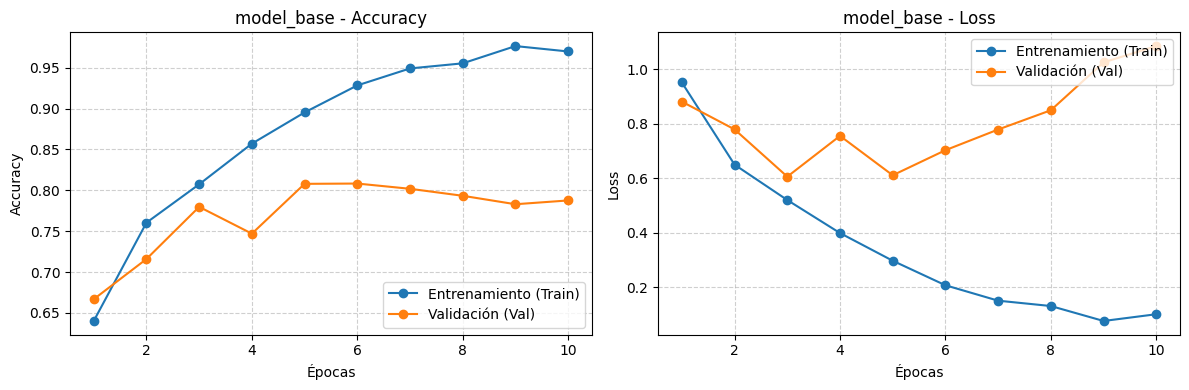

--- Resultados Finales: model_base ---
Mejor Val Accuracy : 80.83% (Época 6)
Test Accuracy      : 78.80%
Test Loss          : 1.0677



In [20]:
evaluar_modelo(model_base, history_base, test_ds, nombre_modelo="model_base")

### Versión 2
A pesar de solo correr por 10 épocas el modelo ya empezaba a psentar overfitting; en esta versión agrego dropout y early stopping con la idea de que ahora podrá aprender por más tiempo antes de deteriorarse.

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.5891 - loss: 1.0575 - val_accuracy: 0.6197 - val_loss: 0.9138
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.7168 - loss: 0.7709 - val_accuracy: 0.7630 - val_loss: 0.6863
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.7666 - loss: 0.6510 - val_accuracy: 0.7527 - val_loss: 0.6620
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8009 - loss: 0.5532 - val_accuracy: 0.7880 - val_loss: 0.5987
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8297 - loss: 0.4631 - val_accuracy: 0.8083 - val_loss: 0.5990
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8498 - loss: 0.4130 - val_accuracy: 0.7994 - val_loss: 0.6276
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8717 - loss: 0.3508 - val_accuracy: 0.8051 - val_loss: 0.6828
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.


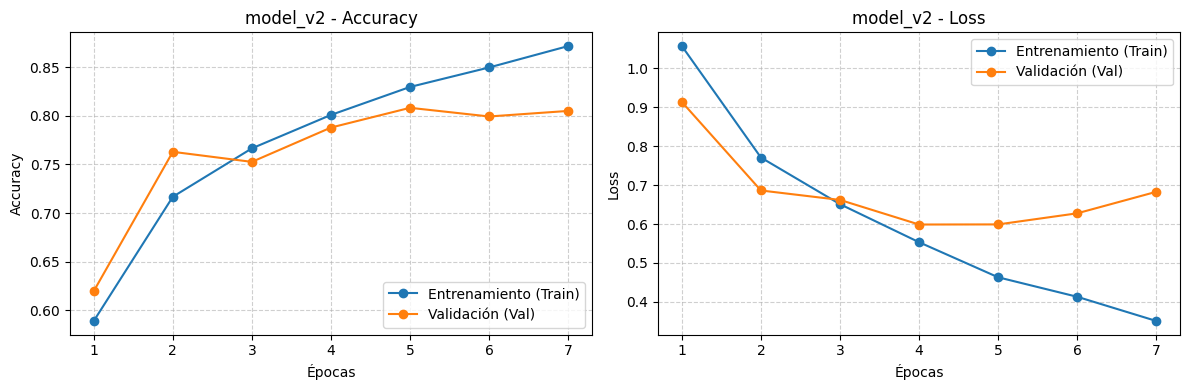

--- Resultados Finales: model_v2 ---
Mejor Val Accuracy : 80.83% (Época 5)
Test Accuracy      : 78.17%
Test Loss          : 0.6032



In [ ]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',          # Vigila la pérdida en validación
    patience=3,                  # Espera 3 épocas sin mejora antes de detenerse
    restore_best_weights=True,   # Crucial: regresa el modelo a su mejor época
    verbose=1
)


model_v2 = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),        # Apaga el 25% de las neuronas

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(len(class_names), activation='softmax')
])

model_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Entrenamiento (subo a 20 épocas, porque ahora hay early stopping)
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

# 4. Evaluar con la función que creaste antes
evaluar_modelo(model_v2, history_v2, test_ds, nombre_modelo="model_v2")

### Versión 3
El dropout sigue presente, ahora pienso que esto puede ser por la simplcidad de la arquitectura. De manera un poco arbitraria, deicidí agregar global average pooling para ver que efecto tiene.

Notas:
1. Después de correrlo una vez, llegó hasta la época 20 sin perdidas en accuracy, así que decidí subir el límite hasta 50, dejé el modelo igual y solo mostré el entrenamiento con límite de 50.
2. Extrañamente, para todas las épocas, excepto por la 15 el modelo tuvo mejor accuracy con los datos de prueba que los de entrenamiento.

Epoch 1/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.3766 - loss: 1.4331 - val_accuracy: 0.4815 - val_loss: 1.2273
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.4922 - loss: 1.1878 - val_accuracy: 0.5880 - val_loss: 1.0089
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5867 - loss: 1.0252 - val_accuracy: 0.6507 - val_loss: 0.9037
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.6190 - loss: 0.9632 - val_accuracy: 0.6707 - val_loss: 0.8546
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.6509 - loss: 0.9055 - val_accuracy: 0.6992 - val_loss: 0.8013
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.6588 - loss: 0.8695 - val_accuracy: 0.6472 - val_loss: 0.8247
Epoch 7/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.6773 - loss: 0.8301 - val_accuracy: 0.7074 - val_loss: 0.7563
Epoch 8/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.6921 - loss: 0.8046 - 

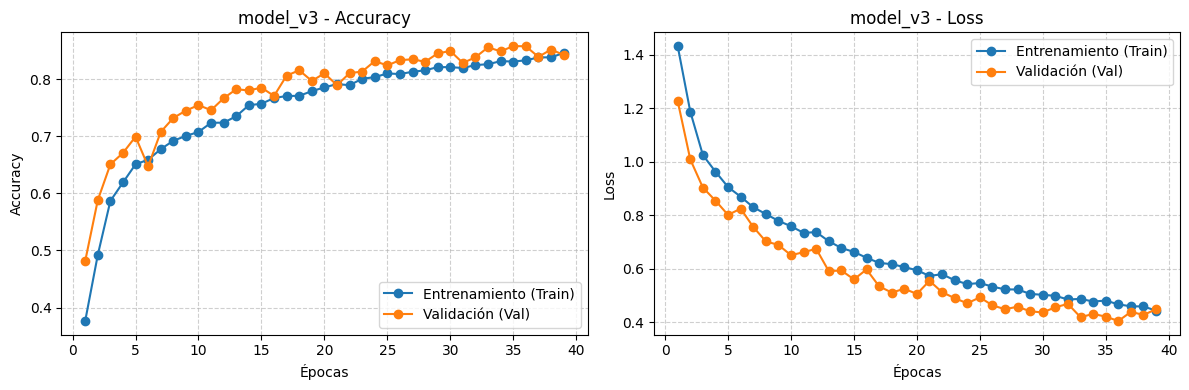

--- Resultados Finales: model_v3 ---
Mejor Val Accuracy : 85.78% (Época 35)
Test Accuracy      : 85.03%
Test Loss          : 0.4165



In [25]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model_v3 = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Único cambio: GlobalAveragePooling2D en lugar de Flatten
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model_v3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

evaluar_modelo(model_v3, history_v3, test_ds, nombre_modelo="model_v3")

### Versión 4
Aumenté la cantidad de filtros en cada paso de maxpooling2d y agregué un bloque nuevo.
Notas:
1. Después de correrlo una vez llegó al mismo nivel de accuracy que el modelo anterior (alredeor de 85%), pero en solo 19 épocas (15 épocas menos) y luego se detuvo por early stopping. Decidí volverlo a correr, pero aumentando la paciencia del early stopping a 5.

Epoch 1/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 37s 104ms/step - accuracy: 0.4217 - loss: 1.3255 - val_accuracy: 0.5421 - val_loss: 1.0376
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 37s 105ms/step - accuracy: 0.5265 - loss: 1.0766 - val_accuracy: 0.5855 - val_loss: 0.9589
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - accuracy: 0.6072 - loss: 0.9503 - val_accuracy: 0.6981 - val_loss: 0.8102
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - accuracy: 0.6723 - loss: 0.8471 - val_accuracy: 0.7341 - val_loss: 0.7005
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - accuracy: 0.7070 - loss: 0.7879 - val_accuracy: 0.7769 - val_loss: 0.6390
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step - accuracy: 0.7390 - loss: 0.7071 - val_accuracy: 0.7862 - val_loss: 0.5958
Epoch 7/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - accuracy: 0.7530 - loss: 0.6774 - val_accuracy: 0.7847 - val_loss: 0.5850
Epoch 8/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 39s 111ms/step - accuracy: 0.7715 - loss: 0

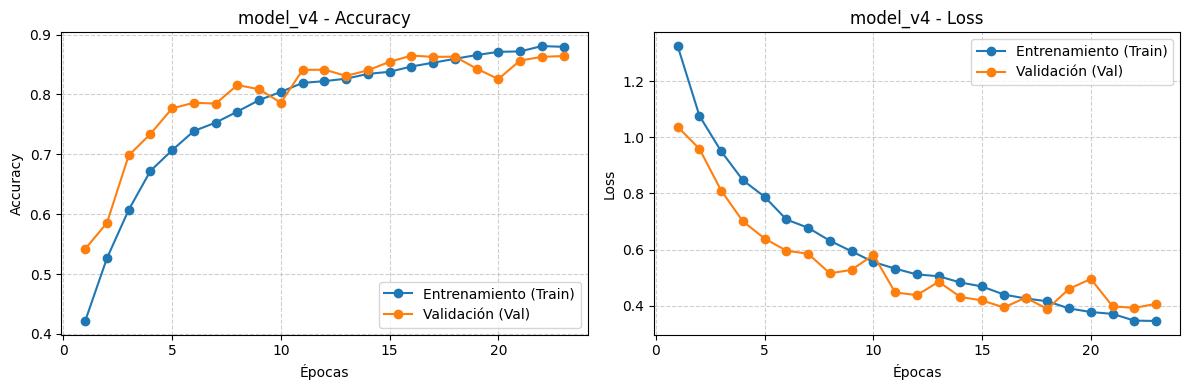

--- Resultados Finales: model_v4 ---
Mejor Val Accuracy : 86.49% (Época 16)
Test Accuracy      : 86.00%
Test Loss          : 0.3963



In [27]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_v4 = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Único cambio: GlobalAveragePooling2D en lugar de Flatten
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model_v4.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v4 = model_v4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

evaluar_modelo(model_v4, history_v4, test_ds, nombre_modelo="model_v4")

### Matriz de confusión
Como no estoy seguro de cómo mejorar esta arquitectura (sin solo hacer prueba y error), pensé que podría ser útil identificar si hay un cesgo en los errores por medio de una matriz de confusión.

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step


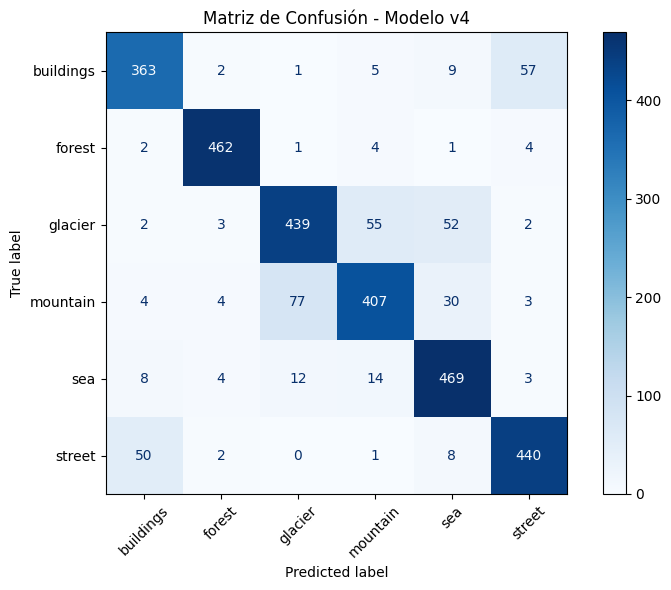

Reporte de Clasificación por Clase:

              precision    recall  f1-score   support

   buildings       0.85      0.83      0.84       437
      forest       0.97      0.97      0.97       474
     glacier       0.83      0.79      0.81       553
    mountain       0.84      0.78      0.81       525
         sea       0.82      0.92      0.87       510
      street       0.86      0.88      0.87       501

    accuracy                           0.86      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.86      0.86      0.86      3000



In [ ]:
# Extraer las etiquetas
y_true = np.concatenate([y for x, y in test_ds], axis=0)

y_pred_probs = model_v4.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')
plt.title('Matriz de Confusión - Modelo v4')
plt.tight_layout()
plt.show()

# Reporte detallado por clase
print("Reporte de Clasificación por Clase:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

### Versión 5
Agregué batch normalization.

Epoch 1/50


c:\Users\mauve\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 96s 267ms/step - accuracy: 0.6220 - loss: 0.9989 - val_accuracy: 0.3282 - val_loss: 1.8432
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 79s 226ms/step - accuracy: 0.7277 - loss: 0.7444 - val_accuracy: 0.6682 - val_loss: 0.8564
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 80s 228ms/step - accuracy: 0.7623 - loss: 0.6607 - val_accuracy: 0.5855 - val_loss: 1.3172
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 91s 260ms/step - accuracy: 0.7831 - loss: 0.6123 - val_accuracy: 0.7894 - val_loss: 0.5599
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 97s 277ms/step - accuracy: 0.7937 - loss: 0.5757 - val_accuracy: 0.7320 - val_loss: 0.7736
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 100s 285ms/step - accuracy: 0.8033 - loss: 0.5530 - val_accuracy: 0.7651 - val_loss: 0.6027
Epoch 7/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 100s 284ms/step - accuracy: 0.8098 - loss: 0.5248 - val_accuracy: 0.5353 - val_loss: 1.6067
Epoch 8/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 93s 266ms/step - accuracy: 0.8255 - loss: 0.4971 - v

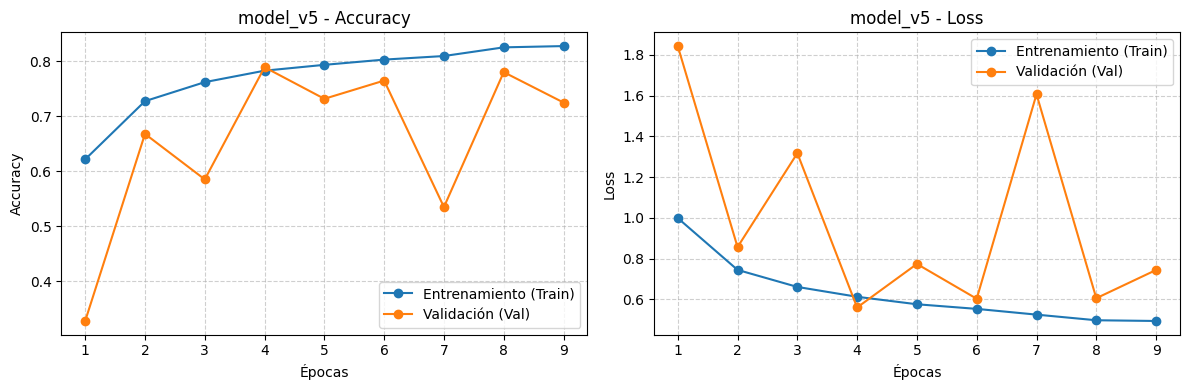

--- Resultados Finales: model_v5 ---
Mejor Val Accuracy : 78.94% (Época 4)
Test Accuracy      : 78.70%
Test Loss          : 0.5676



In [34]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_v5 = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(256, (3, 3), use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model_v5.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v5 = model_v5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

evaluar_modelo(model_v5, history_v5, test_ds, nombre_modelo="model_v5")

### Versión 6
La versión 5, pero sin el dropout, para poder ver el efecto del batch normalization.

In [2]:
from tensorflow.keras import callbacks

Epoch 1/50


c:\Users\mauve\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 88s 247ms/step - accuracy: 0.6330 - loss: 0.9462 - val_accuracy: 0.3656 - val_loss: 1.5908
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 88s 250ms/step - accuracy: 0.7323 - loss: 0.7266 - val_accuracy: 0.6550 - val_loss: 0.8772
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 88s 249ms/step - accuracy: 0.7688 - loss: 0.6490 - val_accuracy: 0.7017 - val_loss: 0.7086
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 103s 294ms/step - accuracy: 0.7789 - loss: 0.6067 - val_accuracy: 0.7509 - val_loss: 0.6424
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 102s 290ms/step - accuracy: 0.7958 - loss: 0.5579 - val_accuracy: 0.7887 - val_loss: 0.6135
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 105s 298ms/step - accuracy: 0.8119 - loss: 0.5358 - val_accuracy: 0.8407 - val_loss: 0.4430
Epoch 7/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 106s 303ms/step - accuracy: 0.8182 - loss: 0.5043 - val_accuracy: 0.8047 - val_loss: 0.5184
Epoch 8/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 104s 295ms/step - accuracy: 0.8249 - loss: 0.4833 

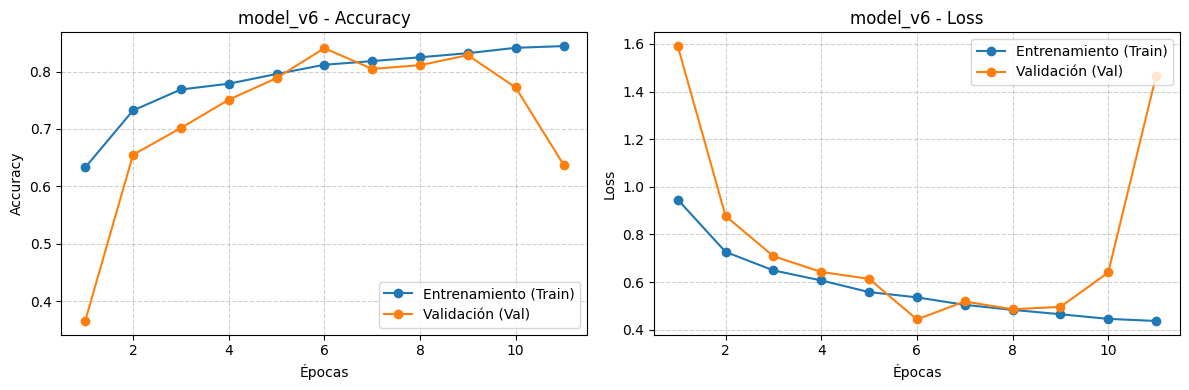

--- Resultados Finales: model_v6 ---
Mejor Val Accuracy : 84.07% (Época 6)
Test Accuracy      : 82.33%
Test Loss          : 0.4760



In [11]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_v6= models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation='softmax')
])

model_v6.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v6 = model_v6.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

evaluar_modelo(model_v6, history_v6, test_ds, nombre_modelo="model_v6")

### Versión 7
No supe qupe pensar sobre el comportamiento anterior en que el aprendizaje iba bien y estable hast un punto en que falla completamente. Pensé que quizás era similar a como learning rates muy altos o bajos hacían que gradient descent pudiera atorarse en mínimos locales u omitir ciertas áreas. Eventualmente encontré que ReduceLROnPlateau, que permite modificar dinámicamente el learnning rate. Probé esto en la versión 6. 

Epoch 1/50


c:\Users\mauve\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 83s 233ms/step - accuracy: 0.6196 - loss: 0.9881 - val_accuracy: 0.4230 - val_loss: 1.4382 - learning_rate: 0.0010
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 239ms/step - accuracy: 0.7369 - loss: 0.7317 - val_accuracy: 0.6921 - val_loss: 0.8841 - learning_rate: 0.0010
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 83s 236ms/step - accuracy: 0.7573 - loss: 0.6625 - val_accuracy: 0.7555 - val_loss: 0.6540 - learning_rate: 0.0010
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 238ms/step - accuracy: 0.7892 - loss: 0.6032 - val_accuracy: 0.6091 - val_loss: 1.1143 - learning_rate: 0.0010
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.8006 - loss: 0.5736
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/351 ━━━━━━━━━━━━━━━━━━━━ 91s 260ms/step - accuracy: 0.8006 - loss: 0.5736 - val_accuracy: 0.6557 - val_loss: 0.8641 - learning_rate: 0.0010
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 99s 283ms/step - accuracy: 0.8270 - loss: 0

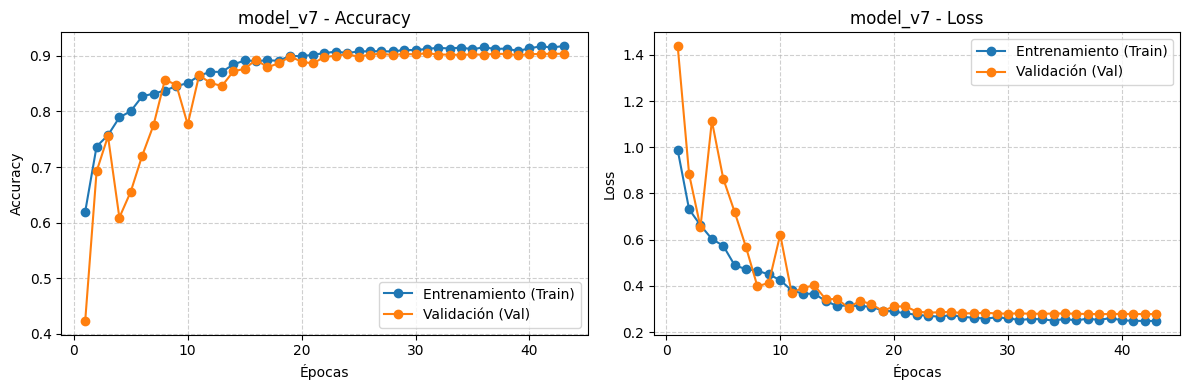

--- Resultados Finales: model_v7 ---
Mejor Val Accuracy : 90.48% (Época 31)
Test Accuracy      : 89.33%
Test Loss          : 0.2982



In [12]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

model_v7= models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation='softmax')
])

model_v7.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v7 = model_v7.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping, reduce_lr]
)

evaluar_modelo(model_v7, history_v7, test_ds, nombre_modelo="model_v7")

## Resultados
La inclusión del ReduceLROnPlateau mejoró drasticamente el rendimiento del modelo, considero que vale la pena regresar a modelos anteriores y ver si tiene un efecto similar ,pero dado que también aumentaron los tiempos de entrenamiento, ya no tengo tiempo para realizar más pruebas. Estos son los resultados del modelo versión 7 con los datos de prueba (que no ha visto previamente).

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.8933 - loss: 0.2982

--- Resultados Finales: model_v7 (Test Set) ---
Test Accuracy : 89.33%
Test Loss     : 0.2982



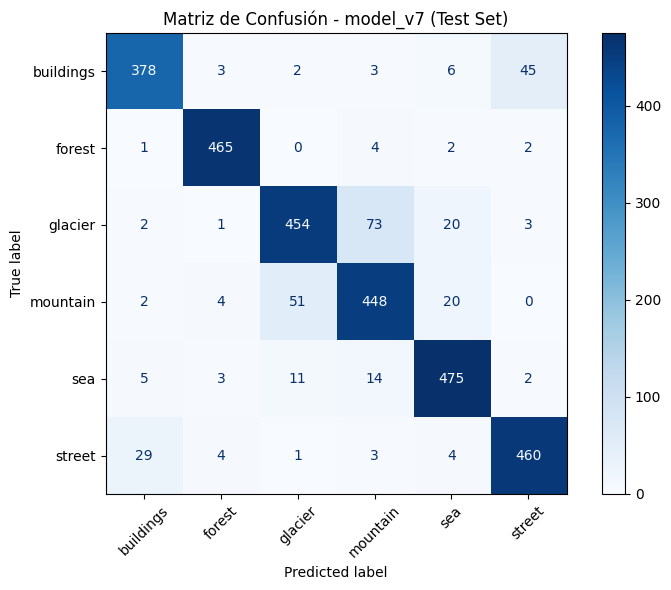

Reporte de Clasificación por Clase:

              precision    recall  f1-score   support

   buildings       0.91      0.86      0.89       437
      forest       0.97      0.98      0.97       474
     glacier       0.87      0.82      0.85       553
    mountain       0.82      0.85      0.84       525
         sea       0.90      0.93      0.92       510
      street       0.90      0.92      0.91       501

    accuracy                           0.89      3000
   macro avg       0.90      0.89      0.89      3000
weighted avg       0.89      0.89      0.89      3000



In [14]:
test_loss, test_acc = model_v7.evaluate(test_ds, verbose=1)
print(f"\n--- Resultados Finales: model_v7 (Test Set) ---")
print(f"Test Accuracy : {test_acc * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}\n")

y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred_probs = model_v7.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Matriz de confusión
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')
plt.title('Matriz de Confusión - model_v7 (Test Set)')
plt.tight_layout()
plt.show()

# Reporte
print("Reporte de Clasificación por Clase:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

Se obtien un accuracy de 89% con varianza significativa dependiendo de la categoría. Forest tiene un f1-score del 97%, mientras que Mountain baja hasta 84%. El rendimiento es bueno, pero hay claro espacio para mejoría, en particular, cambios siguientes deberían de estar focalizados hacía la diferenciación entre categorías de glaciares y montañas.

In [15]:
model_v7.save("modelo_intel_v7.keras")